
# 🚦 Data Exercise - Day 1

> **How to use this notebook**
> - Run this Notebook on your computer or [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/drive//100A8JjF1InvPo6A-y1tiuea56cnV0mA_)
> - Spaces marked **🛠️ _Parameters** are the *only* places you should change code at first.
> - Each section starts with **Tasks** and **Questions** to focus your analysis.
> - There are comments to key code cells to explain *why* and *how* we do things.
> - You have 45 mins to explore the data, choose 3-4 exercises to fit the time. Of course you can explore more if you have enough time.

----


In [343]:
from pathlib import Path
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib import colormaps as mpl_cmaps  
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize
from matplotlib.ticker import MultipleLocator, FormatStrFormatter
from matplotlib.colors import TwoSlopeNorm
from matplotlib.lines import Line2D
import matplotlib.dates as mdates
from matplotlib.patches import Rectangle



---
## 1. Data Exploration (~10 min)
### *Tasks* 
- Inspect dataset structure (variables, time span, sensors, incidents).
- Perform basic statistics (mean speeds, flows, lane utilization).

### *Questions*

- What dates are available? How many sensors and at what spacing?
- What is the aggregation interval (1 or 5 minutes)? Are flows **veh/h** or per-interval?
- Are flows cross-section totals (sum over lanes) or per-lane?
- Do you see missing values or obvious detector outages? How frequent?

> **Tips:** 
- Start by printing `day_table`, checking how many files/days are available
- Choose a day, e.g., `DAY = 3`, to inspect dataset structure (variables, time span, sensors, incidents), and perform basic statistics (mean speeds, flows, lane utilization).

In [ ]:
DATA_DIR = Path("/dataset/")
PATTERN  = "* - A4L - km. 1.1-47 - uitvoer.txt"   # adjust if needed (e.g., km. 1-47)

files = sorted(DATA_DIR.rglob(PATTERN))
rows  = []
for f in files:
    m = re.search(r"\d{4}-\d{2}-\d{2}", f.name)
    if m:
        rows.append({"date": m.group(0), "path": f})

day_table = (pd.DataFrame(rows).sort_values("date").reset_index(drop=True))
if day_table.empty:
    raise FileNotFoundError(f"No files matched in\n  {DATA_DIR}\npattern: {PATTERN}")

day_table.index.name = "DAY"
print("Available days (pick a number for DAY):")
print(day_table[["date"]])

Available days (pick a number for DAY):
           date
DAY            
0    2024-06-24
1    2024-06-25
2    2024-06-26
3    2024-06-27
4    2024-06-28
5    2025-06-16
6    2025-06-17
7    2025-06-18
8    2025-06-19
9    2025-06-20
10   2025-06-23
11   2025-06-24
12   2025-06-25
13   2025-06-26


In [345]:
# ======= 🛠️ _Parameters (edit here) =======
DAY = 3               # single day index (see printed day_table)

FILE = day_table.loc[DAY, "path"]
print(f"\nSelected [{DAY}] {day_table.loc[DAY,'date']}  ->  {FILE.name}")

# ========= HELPERS =========
def _date_from_filename(p: Path) -> str:
    return re.search(r"\d{4}-\d{2}-\d{2}", p.name).group(0)

def _attach_date(times: pd.Series, path: Path) -> pd.Series:
    """prepend file date to HH:MM and parse to Timestamp"""
    d = _date_from_filename(path)
    return pd.to_datetime(times.astype(str).radd(d + " "))

def tidy(wide: pd.DataFrame, value_name: str) -> pd.DataFrame:
    return (wide.melt(id_vars="time", var_name="km", value_name=value_name)
                .assign(km=lambda d: d["km"].str.replace("km_","",regex=False).astype(float))
                .sort_values(["time","km"]).reset_index(drop=True))

# ========= PARSERS FLOW, SPEED AND TRAVEL TIMES ==========
def parse_matrix(path: Path, title_pat: str, na_sentinel=-1.0) -> pd.DataFrame:
    """For 'Gebruikte intensiteiten' (veh/h) and 'Gebruikte snelheden' (km/h)."""
    lines = path.read_text(encoding="utf-8", errors="ignore").splitlines()
    s = next(i for i,l in enumerate(lines) if re.search(title_pat, l, re.I))
    d = next(i for i in range(s+1, s+10) if re.match(r"\s*-{3,}\s*$", lines[i]))
    h = next(i for i in range(d+1, d+6) if re.search(r"\d+\.\d{3}", lines[i]))

    kms  = re.findall(r"\d+\.\d{3}", lines[h])
    cols = ["time"] + [f"km_{k}" for k in kms]

    rows = []
    for ln in lines[h+1:]:
        m = re.match(r"^(\d{2}:\d{2})\s+(.*)$", ln.strip())
        if not m:
            if rows: break
            else:    continue
        vals = [float(x) for x in re.findall(r"-?\d+(?:\.\d+)?", m.group(2))]
        vals = (vals + [np.nan]*len(kms))[:len(kms)]
        vals = [np.nan if v == na_sentinel else v for v in vals]
        rows.append([m.group(1)] + vals)

    df = pd.DataFrame(rows, columns=cols)
    df["time"] = _attach_date(df["time"], path)
    return df

def parse_travel_times(path: Path) -> pd.DataFrame:
    """'Berekende reistijden' (handles gap NaNs between avg/sd blocks)."""
    lines = path.read_text(encoding="utf-8", errors="ignore").splitlines()
    s  = next(i for i,l in enumerate(lines) if re.search(r"Berekende reistijden", l, re.I))
    h  = next(i for i in range(s, s+15) if re.search(r"\bMethode\b", lines[i], re.I))

    hdr   = re.findall(r"(?:Ref\.)|\d+", lines[h])                # e.g. ['Ref.', '1','2','3','Ref.','1','2','3']
    pivot = hdr.index("Ref.", 1) if hdr.count("Ref.")>=2 else len(hdr)//2
    avg_names = [("ref_avg" if t=="Ref." else f"m{t}_avg") for t in hdr[:pivot]]
    sd_names  = [("ref_sd"  if t=="Ref." else f"m{t}_sd")  for t in hdr[pivot:]]

    rows = []
    for ln in lines[h+1:]:
        m = re.match(r"^(\d{2}:\d{2})\s+(.*)$", ln.strip())
        if not m:
            if rows: break
            else:    continue
        toks = re.findall(r"(?:NaN|-?\d+(?:\.\d+)?)", m.group(2))
        nums = [np.nan if t.lower()=="nan" else float(t) for t in toks]
        avgs = (nums[:len(avg_names)] + [np.nan]*len(avg_names))[:len(avg_names)]
        rest = nums[len(avg_names):]
        while len(rest) > len(sd_names) and pd.isna(rest[0]):   # drop gap NaNs
            rest = rest[1:]
        sds  = (rest[:len(sd_names)] + [np.nan]*len(sd_names))[:len(sd_names)]
        rows.append([m.group(1)] + avgs + sds)

    df = pd.DataFrame(rows, columns=["time"] + avg_names + sd_names)
    df["time"] = _attach_date(df["time"], path)
    return df

# ========= PARSER: Network indicators (TDT/TTS/TD/FZ/NS) =========
def parse_network_indicators(path: Path) -> pd.DataFrame:
    """
    Parse the section 'Netwerk indicatoren per periode en per wegnummer'
    Columns shown in the file (example):
        A4-TDT (vrt.km), A4-TTS (vrt.uren), A4-TD (vrt.uren), A4-FZ (km.min), A4-NS (km/h)
    Returns a wide df with:
        time, a4_tdt, a4_tts, a4_td, a4_fz, a4_ns
    """
    lines = path.read_text(encoding="utf-8", errors="ignore").splitlines()
   
    # Find the section start
    s = next(i for i, ln in enumerate(lines) if re.search(r"Netwerk indicatoren", ln, flags=re.I))
    # Find dashed separator after the title
    d = next(i for i in range(s+1, min(s+10, len(lines))) if re.match(r"\s*-{3,}\s*$", lines[i]))
    # Header line (contains 'A4-')
    h = next(i for i in range(d+1, min(d+6, len(lines))) if re.search(r"A4-", lines[i]))

    # Grab the A4- column tokens in order
    hdr_tokens = re.findall(r"(A4-[A-Za-z]+)", lines[h])
    # map to short, clean names
    short = {"A4-TDT":"a4_tdt", "A4-TTS":"a4_tts", "A4-TD":"a4_td", "A4-FZ":"a4_fz", "A4-NS":"a4_ns"}
    col_names = ["time"] + [short.get(tok, tok.lower().replace("-", "_")) for tok in hdr_tokens]
    n_expected = len(col_names) - 1

    # Parse rows that start with HH:MM
    rows = []
    for ln in lines[h+1:]:
        m = re.match(r"^(\d{2}:\d{2})\s+(.*)$", ln.strip())
        if not m:
            if rows: break
            else:    continue
        nums = re.findall(r"-?\d+(?:\.\d+)?", m.group(2))
        vals = [float(x) for x in nums]
        # keep only the first n_expected values and pad if short
        vals = (vals + [np.nan]*n_expected)[:n_expected]
        # -1.00 is a common 'no data' sentinel here → NaN
        vals = [np.nan if v == -1.0 else v for v in vals]
        rows.append([m.group(1)] + vals)

    df = pd.DataFrame(rows, columns=col_names)
    # attach the date from filename
    df["time"] = _attach_date(df["time"], path)
    return df

# ========= LOAD and QUICK EXPLORATION =========
flow_w  = parse_matrix(FILE, r"Gebruikte intensiteiten")  # veh/h
speed_w = parse_matrix(FILE, r"Gebruikte snelheden")      # km/h
tt_w    = parse_travel_times(FILE)                        # sec (Ref/M1–M3)
network = parse_network_indicators(FILE)

flow  = tidy(flow_w,  "flow_veh_h")
speed = tidy(speed_w, "speed_kmh")

# print("\nShapes →", "flow", flow.shape, "| speed", speed.shape, "| tt", tt_w.shape)
print("\nTime span:", flow_w['time'].min(), "→", flow_w['time'].max())
print("\nLanes in total: 4")
print(f"\nMeans (all km & times) → Speed: {speed['speed_kmh'].mean():.1f} km/h | Flow: {flow['flow_veh_h'].mean():.0f} veh/h")
print("flow and speed:")
print(flow.head())
print(speed.head())

print("\nTravel time (Ref & M3) quick stats:")
cols = [c for c in ["ref_avg","m1_avg","m2_avg","m3_avg","m4_avg"] if c in tt_w.columns]
print(tt_w[cols].describe().round(2))

print("\nTravel time summary (first 8 rows):")
keep = [c for c in ["time","ref_avg","m3_avg","m3_sd"] if c in tt_w.columns]
print(tt_w[keep].head(8).to_string(index=False, float_format=lambda x: f"{x:.2f}"))

print("\nNetwork indicators (first 12 rows) — units in brackets:")
print("(TDT=vrt.km, TTS=vrt.uren, TD=vrt.uren, FZ=km.min, NS=km/h)\n")
print(network.head(12).to_string(index=False, float_format=lambda x: f"{x:.2f}"))

print("\nQuick stats by time-of-day (means):")
print(network.drop(columns="time").mean().round(2))


Selected [3] 2024-06-27  ->  2024-06-27 - A4L - km. 1.1-47 - uitvoer.txt

Time span: 2024-06-27 06:00:00 → 2024-06-27 20:55:00

Lanes in total: 4

Means (all km & times) → Speed: 95.4 km/h | Flow: 4420 veh/h
flow and speed:
                 time   km  flow_veh_h
0 2024-06-27 06:00:00  1.1      5640.0
1 2024-06-27 06:00:00  1.5      6000.0
2 2024-06-27 06:00:00  2.0      6336.0
3 2024-06-27 06:00:00  2.4      6420.0
4 2024-06-27 06:00:00  2.7      6420.0
                 time   km  speed_kmh
0 2024-06-27 06:00:00  1.1      95.04
1 2024-06-27 06:00:00  1.5      95.95
2 2024-06-27 06:00:00  2.0      96.42
3 2024-06-27 06:00:00  2.4      96.96
4 2024-06-27 06:00:00  2.7      97.63

Travel time (Ref & M3) quick stats:
       ref_avg  m1_avg  m2_avg   m3_avg  m4_avg
count    180.0     0.0     0.0   180.00     0.0
mean    1652.4     NaN     NaN  1983.23     NaN
std        0.0     NaN     NaN   360.32     NaN
min     1652.4     NaN     NaN  1570.43     NaN
25%     1652.4     NaN     NaN  1736


### 🗂️ Data Description & File Naming

- **File names** include the date and the corridor segment, e.g.  
  `2024-06-24 - A4L - km. 1.1-47 - uitvoer.txt`  
  - `A4L` = A4, direction L  
  - `km. 1.1-47` = sensor coverage (hectometer posts 1.1 to 47)
- We extract the **date** from the filename with a regex (`\d{4}-\d{2}-\d{2}`) and attach it to HH:MM timestamps.
- `parse_matrix()` reads blocks like **Gebruikte intensiteiten** (flow) and **Gebruikte snelheden** (speed).  
  - Flows are reported as **veh/h** for each interval (5 min). Values are usually **cross-section totals** (sum over lanes).
  - Speeds are in **km/h** (interval mean).  
- **Density** is derived as `k = q / v` (veh/km). For **per-lane** comparisons to theory, divide both flow and density by the number of lanes `LANES`.



---
## 2. Fundamental Diagram (FD) (~15 min)
### *Tasks*
- Use Python to plot flow vs. density (or occupancy proxy).
- Identify free-flow branch, capacity point, and congested branch.
- Compare diagrams across different days.


### *Questions*
- Where is the **free-flow branch**? Estimate its slope (≈ free-flow speed).
- Where does the **capacity point** (max flow) occur? What is the corresponding density?
- How does the **congested branch** look? What is the backward wave speed (slope)?
- Compare two different days: do they have similar capacity? What might explain differences?
- Are flows per **cross-section** or **per-lane**? Normalize appropriately when comparing to theory (~2000 veh/h/lane).

> **🛠️ _Parameters:** change `DAYS` in the cell.


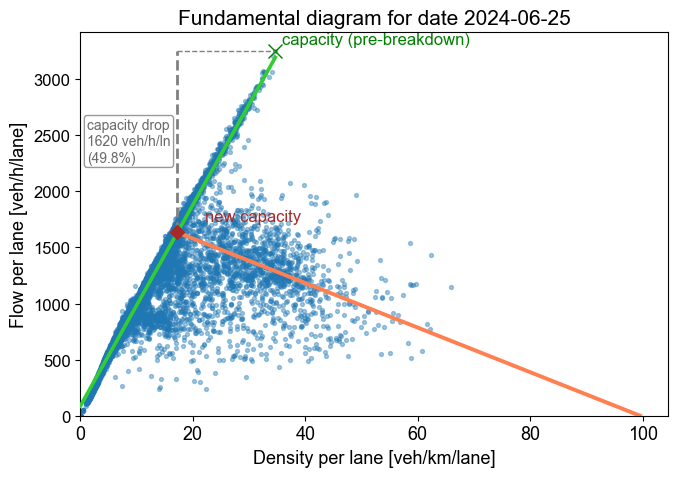


Per-lane FD summary per selected day:

Date: 2024-06-25
  Data points:            15840
  Capacity flow:          3255 veh/h/lane
  Capacity density:       34.67 veh/km/lane
  Speed at capacity:      93.9 km/h
  Free-flow speed (vf):   89.6 km/h
  Congested wave speed w: -19.88 km/h
  Jam density (est.):     99.5 veh/km/lane
  New capacity (∩):       1635 veh/h/lane
  Capacity drop:          1620 veh/h/lane (49.8%)


In [364]:
# ==== Imports ====
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =================== CONFIG ===================
DAYS = [1]
LANES = 4
SPEED_FF = 70.0
ALPHA = 0.4

# =================== GLOBAL STYLE CONFIG ===================
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 14,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 13,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
})

# ===== load selected days =====
def _load_fd_rows(day_idxs):
    out = []
    for d in ([day_idxs] if isinstance(day_idxs, int) else day_idxs):
        p = day_table.loc[d, "path"]
        date_str = day_table.loc[d, "date"]

        fw = parse_matrix(p, r"Gebruikte intensiteiten")   # veh/h
        sw = parse_matrix(p, r"Gebruikte snelheden")       # km/h
        f  = tidy(fw, "flow_veh_h")
        s  = tidy(sw, "speed_kmh")

        df = (f.merge(s, on=["time","km"], how="inner")
                .assign(density_veh_km=lambda d: d["flow_veh_h"]/d["speed_kmh"])
                .assign(date=date_str))
        out.append(df)
    return pd.concat(out, ignore_index=True)

fd = _load_fd_rows(DAYS).dropna(subset=["flow_veh_h","speed_kmh","density_veh_km"])
fd = fd.assign(
    flow_per_lane      = fd["flow_veh_h"] / LANES,
    density_per_lane   = fd["density_veh_km"] / LANES
)

# =================== helpers ===================
def capacity_point(df, kcol="density_per_lane", qcol="flow_per_lane"):
    i = df[qcol].idxmax()
    return df.loc[i, [kcol, qcol, "speed_kmh"]].to_dict()

def fit_branch(df, x="density_per_lane", y="flow_per_lane"):
    X = np.c_[np.ones(len(df)), df[x].to_numpy()]
    yv = df[y].to_numpy()
    a, b = np.linalg.lstsq(X, yv, rcond=None)[0]
    return float(a), float(b)

def interior_congestion_fit(dday, cap_k, cap_q,
                            speed_ff=SPEED_FF, kmin_frac=0.90,
                            nbins=22, q=0.50):
    cg = dday[(dday["density_per_lane"] >= kmin_frac * cap_k) &
              (dday["speed_kmh"] < speed_ff - 5)].copy()
    if len(cg) < 30: return np.nan, np.nan

    x = cg["density_per_lane"].to_numpy()
    y = cg["flow_per_lane"].to_numpy()
    lo, hi = np.percentile(x, 5), np.percentile(x, 99.5)
    bins = np.linspace(lo, hi, nbins + 1)

    xc, yc = [], []
    for lo_b, hi_b in zip(bins[:-1], bins[1:]):
        m = (x >= lo_b) & (x < hi_b)
        if m.sum() >= 8:
            xc.append(0.5*(lo_b+hi_b))
            yc.append(np.nanpercentile(y[m], q*100))

    xc, yc = np.asarray(xc), np.asarray(yc)
    if len(xc) < 3:
        return np.nan, np.nan

    X = np.c_[np.ones(len(xc)), xc]
    a, b = np.linalg.lstsq(X, yc, rcond=None)[0]
    if b > 0:
        b = 0.0
    return float(a), float(b)

def line_intersection(a1, b1, a2, b2):
    if not (np.isfinite(a1) and np.isfinite(b1) and np.isfinite(a2) and np.isfinite(b2)):
        return np.nan, np.nan
    if abs(b1 - b2) < 1e-9:
        return np.nan, np.nan
    k_star = (a2 - a1) / (b1 - b2)
    q_star = a1 + b1 * k_star
    return float(k_star), float(q_star)

# =================== plot PER-LANE FD ===================
fig, ax = plt.subplots(figsize=(7,5))
summary_results = []

for day, dday in fd.groupby("date", sort=True):
    # scatter
    ax.scatter(dday["density_per_lane"], dday["flow_per_lane"], s=8, alpha=ALPHA)

    # old capacity (green x)
    cap = capacity_point(dday)
    cap_k, cap_q, cap_v = cap["density_per_lane"], cap["flow_per_lane"], cap["speed_kmh"]
    ax.plot(cap_k, cap_q, marker="x", ms=10, color="green")
    ax.annotate("capacity (pre-breakdown)", (cap_k, cap_q),
                xytext=(5,5), textcoords="offset points", fontsize=12, color="green")

    # free-flow fit (limegreen)
    ff = dday[dday["speed_kmh"] >= SPEED_FF]
    a1 = b1 = np.nan
    if len(ff) > 10:
        a1, b1 = fit_branch(ff)
        x_max_ff = max(cap_k, ff["density_per_lane"].quantile(0.97))
        xs_ff = np.linspace(0, x_max_ff, 200)
        ax.plot(xs_ff, a1 + b1*xs_ff, linewidth=2.6, color="limegreen", zorder=15)

    # congested fit (coral)
    a2, b2 = interior_congestion_fit(dday, cap_k, cap_q)
    k_star, q_star = line_intersection(a1, b1, a2, b2)

    if np.isfinite(k_star) and np.isfinite(q_star):
        k_jam = -a2/b2 if (np.isfinite(a2) and np.isfinite(b2) and b2 < 0) else np.nan
        x_end_cg = k_jam if np.isfinite(k_jam) else dday["density_per_lane"].max()
        xs_cg = np.linspace(k_star, x_end_cg, 200)
        ys_cg = a2 + b2*xs_cg
        ax.plot(xs_cg, ys_cg, color="coral", lw=2.8, zorder=20)

        # intersection marker (brown)
        ax.plot(k_star, q_star, marker="D", ms=7, color="brown", zorder=25)
        ax.annotate("new capacity", (k_star, q_star),
                    xytext=(20, 8), textcoords="offset points", fontsize=12, color="brown")

        # capacity drop
        cap_drop = cap_q - q_star
        cap_drop_pct = 100.0*cap_drop/cap_q if cap_q > 0 else np.nan

        # dashed helpers (grey)
        ax.vlines(k_star, q_star, cap_q, colors="grey", linestyles="--", linewidth=2)
        ax.hlines(cap_q, k_star, cap_k, colors="grey", linestyles="--", linewidth=1)

        # label box (dimgray text, grey box)
        y_mid = 0.5 * (q_star + cap_q)
        ax.annotate(f"capacity drop\n{cap_drop:.0f} veh/h/ln\n({cap_drop_pct:.1f}%)",
                    (k_star, y_mid), xytext=(-65, 0), textcoords="offset points",
                    ha="left", va="center", fontsize=10, color="dimgray",
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="grey", alpha=0.8))

        summary_results.append({
            "day": day,
            "points": len(dday),
            "q_cap": cap_q,
            "k_cap": cap_k,
            "v_cap": cap_v,
            "vf_est": b1,
            "w_est": b2,
            "k_jam": k_jam,
            "q_new": q_star,
            "cap_drop": cap_drop,
            "cap_drop_pct": cap_drop_pct
        })

ax.set_xlabel("Density per lane [veh/km/lane]")
ax.set_ylabel("Flow per lane [veh/h/lane]")
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
ax.set_title(f"Fundamental diagram for date {day}")
plt.tight_layout()
plt.show()

# =================== PRINT FULL SUMMARY ===================
print("\nPer-lane FD summary per selected day:")
for s in summary_results:
    print(f"\nDate: {s['day']}")
    print(f"  Data points:            {s['points']}")
    print(f"  Capacity flow:          {s['q_cap']:.0f} veh/h/lane")
    print(f"  Capacity density:       {s['k_cap']:.2f} veh/km/lane")
    print(f"  Speed at capacity:      {s['v_cap']:.1f} km/h")
    print(f"  Free-flow speed (vf):   {s['vf_est']:.1f} km/h")
    print(f"  Congested wave speed w: {s['w_est']:.2f} km/h")
    if np.isfinite(s['k_jam']):
        print(f"  Jam density (est.):     {s['k_jam']:.1f} veh/km/lane")
    print(f"  New capacity (∩):       {s['q_new']:.0f} veh/h/lane")
    print(f"  Capacity drop:          {s['cap_drop']:.0f} veh/h/lane ({s['cap_drop_pct']:.1f}%)")



---
## 3. Travel Time Analysis (~10 min)
### *Tasks* 
- Compute average travel times along the motorway stretch per time-of-day.
- Compare peak vs. off-peak and day-to-day variability.

### *Questions*
- How do average travel times vary over the day? Where are the peaks?
- How variable are travel times (SDTT, CoV)? At what hours is variability highest?
- How does Method 3 compare to the reference travel time?
- Day-to-day: which date is "best" (lowest ATT) and which is most unreliable (highest CoV)?

> **🛠️ _Parameters:** change `DAY` in the cells to choose a date.


 Day 3 → Date 2024-06-27


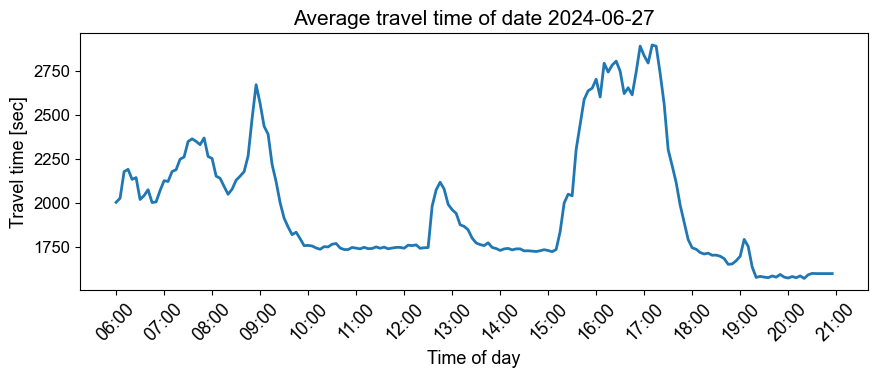

In [367]:
# ========================================================================
# Compute average travel times along the motorway stretch per time-of-day. 
# ========================================================================

DAY = 3               # pick a day number from the printed day_table, e.g., 0 or [0, 2, 5]
METHOD_COL = "m3_avg" 

fpath = day_table.loc[DAY, "path"]
date  = day_table.loc[DAY, "date"]
tt    = parse_travel_times(fpath)

keep = [c for c in ["time","ref_avg","m1_avg","m2_avg","m3_avg"] if c in tt.columns]
tt   = tt[keep].dropna(subset=[METHOD_COL]).copy()
tt["tod"] = tt["time"].dt.floor("5min")
per_tod   = tt.groupby("tod", as_index=False)[METHOD_COL].mean()
per_tod.rename(columns={METHOD_COL:"tt_sec"}, inplace=True)
print(f" Day {DAY} → Date {date}")

# ======= PLOT =======
fig, ax = plt.subplots(figsize=(9,4))
ax.plot(per_tod["tod"], per_tod["tt_sec"], lw=2)
start = per_tod["tod"].iloc[0].replace(hour=6, minute=0)
end   = per_tod["tod"].iloc[0].replace(hour=21, minute=0)
ticks = pd.date_range(start=start, end=end, freq="1h")  # every 1h, you can change
ax.set_xticks(ticks)
ax.set_xticklabels([t.strftime("%H:%M") for t in ticks], rotation=45)
ax.set_title(f"Average travel time of date {date}")
ax.set_xlabel("Time of day")
ax.set_ylabel("Travel time [sec]")

for spine in ax.spines.values():
    spine.set_visible(True)

plt.tight_layout()
plt.show()

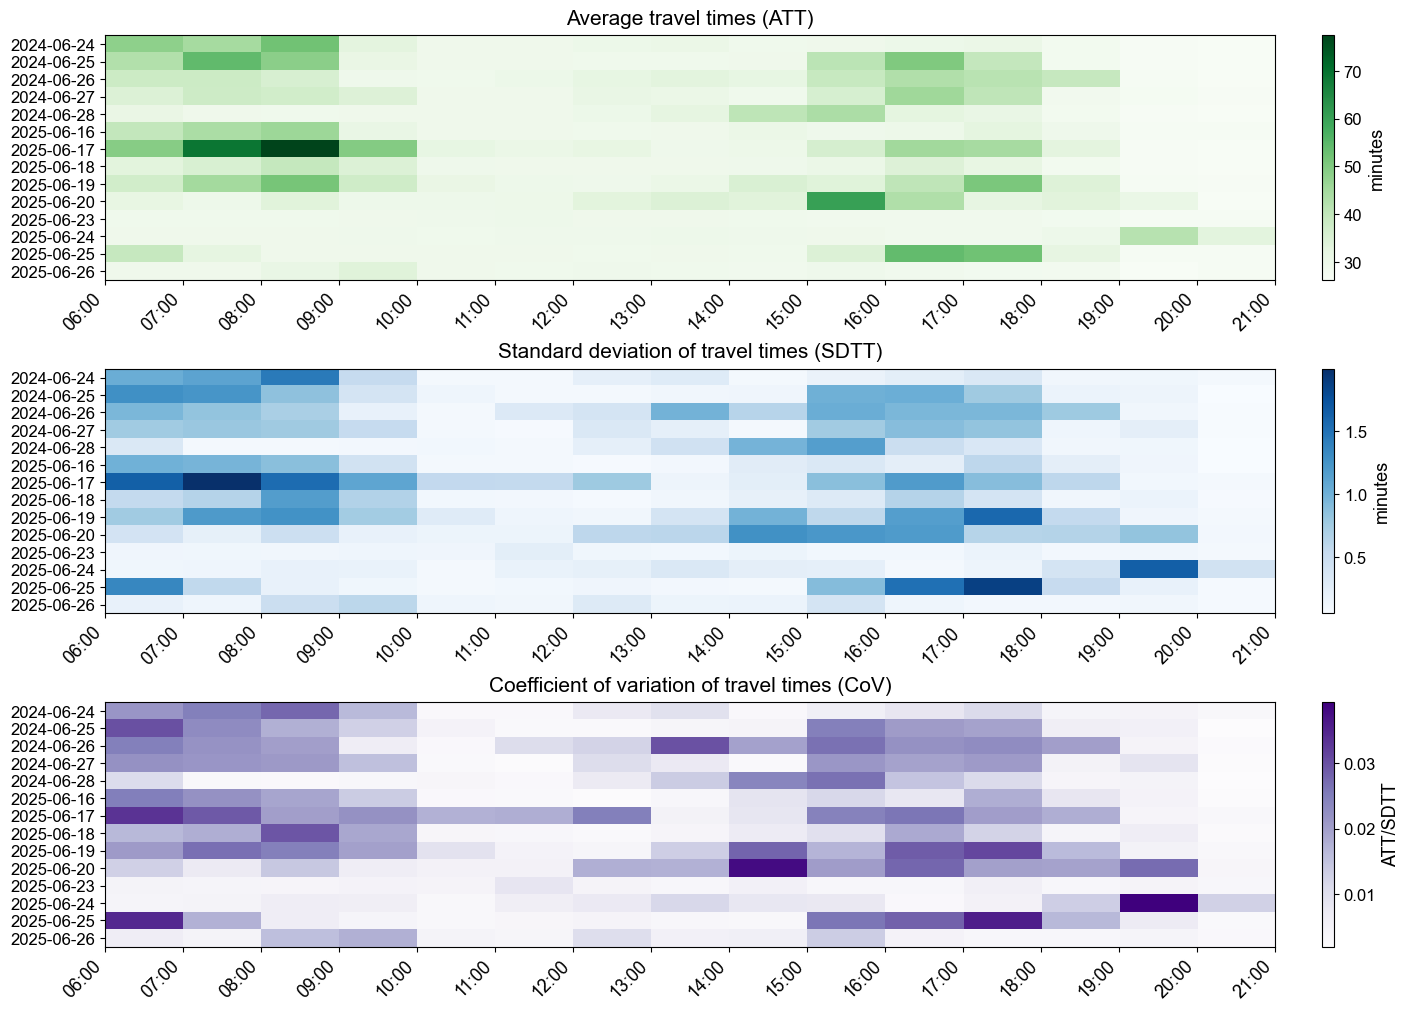

In [349]:
# =======================================================
# Compare peak vs. off-peak and day-to-day variability.
# =======================================================

DAYS = "all"            # Choose days to load: "all"
METHOD_COL = "m3_avg"   # method used for mean travel times, default in the dataset


# =========== Helper function: select which days to use =========== 
def _select_days(sel):
    if sel == "all":
        return list(range(len(day_table)))
    if isinstance(sel, int):
        return [sel]
    return list(sel)

# =========== Load travel time data for the selected days =========== 
def load_tt(selected):
    frames = []
    for d in _select_days(selected):
        f  = day_table.loc[d, "path"]
        tt = parse_travel_times(f)
        keep = [c for c in ["time","m3_avg","m3_sd"] if c in tt.columns]
        # keep only useful columns (timestamp, mean, std dev)
        frames.append(tt[keep].assign(day_idx=d))
    # combine all days into a single DataFrame
    return pd.concat(frames, ignore_index=True)

# =========== Preprocessing: clean and organize time columns =========== 
tt_all = load_tt(DAYS)
tt = tt_all[["time","m3_avg","m3_sd"]].copy()
tt["date"] = tt["time"].dt.date
tt["hour"] = tt["time"].dt.hour
tt = tt[tt["hour"].between(6, 20)]

dates = sorted(tt["date"].unique())
tt["date"] = pd.Categorical(tt["date"], categories=dates, ordered=True)

# =========== Pivot tables: compute daily/hourly summaries =========== 
# ATT: Average Travel Time in minutes
ATT  = (tt.pivot_table(index="date", columns="hour", values="m3_avg",
                       aggfunc="mean", observed=False) / 60.0).reindex(dates)
# SDTT: Standard Deviation of Travel Times in minutes
SDTT = (tt.pivot_table(index="date", columns="hour", values="m3_sd",
                       aggfunc="mean", observed=False) / 60.0).reindex(dates)
# CoV: Coefficient of Variation (SDTT / ATT)
CoV = SDTT.divide(ATT.where(ATT > 0))

# =========== Plot heatmaps of ATT, SDTT, CoV ===========
def cmap_with_bad(name):
    return mpl_cmaps.get_cmap(name).with_extremes(bad="#f0f0f0")

def heatmap_hours(ax, data: pd.DataFrame, title: str, cbar_label: str, cmap="viridis"):
    hours = np.sort(data.columns.astype(int))
    data  = data.reindex(columns=hours)
    nrows, ncols = data.shape
    h0, hN = hours[0], hours[-1]

    # imshow expects numeric grid, so map each hour to [h, h+1)
    im = ax.imshow(
        data.to_numpy(),
        aspect="auto",
        interpolation="nearest",
        cmap=cmap,
        extent=(h0, hN + 1, nrows - 0.5, -0.5)  # map each hour to [h, h+1)
    )

    # y-axis: one row per day
    ax.set_yticks(np.arange(nrows))
    ax.set_yticklabels([str(d) for d in data.index])

    # x-axis: one tick per hour
    ax.set_xticks(np.r_[hours, hN + 1])
    ax.set_xticklabels([f"{h:02d}:00" for h in hours] + [f"{hN+1:02d}:00"], rotation=45, ha="right")
    ax.set_xlim(h0, hN + 1)

    # add title + colorbar
    ax.set_title(title, pad=8)
    cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label(cbar_label)

# ======= Create subplots for ATT, SDTT, CoV =======
fig, axes = plt.subplots(3, 1, figsize=(14, 10), constrained_layout=True)
heatmap_hours(axes[0], ATT,  "Average travel times (ATT)",               "minutes", cmap="Greens")
heatmap_hours(axes[1], SDTT, "Standard deviation of travel times (SDTT)", "minutes", cmap="Blues")
heatmap_hours(axes[2], CoV,  "Coefficient of variation of travel times (CoV)", "ATT/SDTT", cmap=cmap_with_bad("Purples"))

plt.show()



---
## 4. Speed Contour Plots (~10 min)
## *Tasks*
- Generate contour plots using notebook templates.
- Identify congestion patterns and anomalies.
- Compare days with and without incidents.

## *Questions*
- Where and when do low-speed regions appear? Do they form upstream-moving "tongues"?
- Are there anomalies that could be incidents? Do they align with the incident table?
- Compare a day **with** incident vs **without**: what differences do you see?

> **🛠️ _Parameters:** change `DAY` to choose a date.


Available dates: ['2024-06-24' '2024-06-25' '2024-06-26' '2024-06-27' '2024-06-28'
 '2025-06-16' '2025-06-17' '2025-06-18' '2025-06-19' '2025-06-20'
 '2025-06-23' '2025-06-24' '2025-06-25' '2025-06-26']


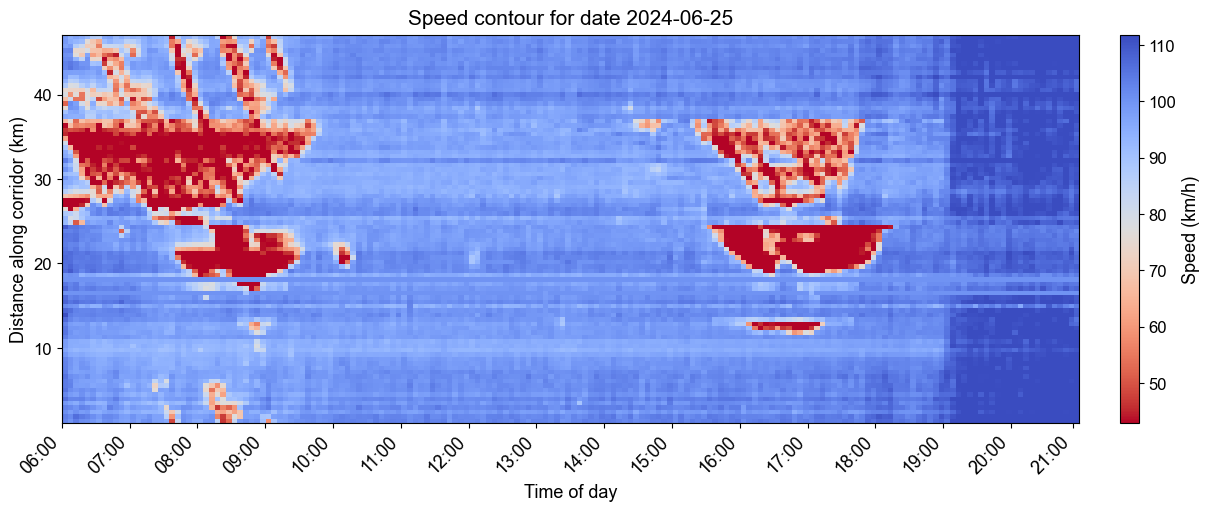

In [350]:
# ==========================================
# 3. Contour plot of speed over time-of-day.
# ==========================================

# ---------------- CONFIG ----------------
DAYS = [1]                                 # choose days by index from `day_table`, e.g. [0], [2], [3]
TIME_START, TIME_END = "06:00", "20:59"    # time window to plot
SPEED_CMAP = "coolwarm_r"                  # color scheme for speeds (red=slow, blue=fast)
FLIP_DISTANCE = True                       # set True to have distance increase downward

# ======= Load speed data for a given day index =======
def load_speed_for_day(day_idx: int) -> pd.DataFrame:
    """
    Parse 'Gebruikte snelheden' from the file at day_table[day_idx].
    Returns long-form df with columns: time, km, speed_kmh
    """
    p = day_table.loc[day_idx, "path"]
    wide = parse_matrix(p, r"Gebruikte\s+snelheden")  # (km/h)
    spd = tidy(wide, "speed_kmh")[["time", "km", "speed_kmh"]]
    spd["time"] = pd.to_datetime(spd["time"])
    spd["km"] = spd["km"].astype(float)
    spd["speed_kmh"] = spd["speed_kmh"].astype(float)
    return spd

dates_all = day_table["date"].to_numpy()
print("Available dates:", dates_all)

# ======= Build a grid of speeds (time vs. distance) =======
def build_speed_grid_for_date(date):
    """Return a pivot table: rows=time, cols=km, values=speed_kmh, restricted to TIME_START–TIME_END."""
    # NOTE: this function will use the module-level variable 'speed'
    # which is set for the selected day inside the loop below.
    df = speed.loc[:, ["time","km","speed_kmh"]].copy()
    if df.empty:
        return None, None, None

    Z = df.pivot_table(index="time", columns="km", values="speed_kmh", aggfunc="mean").sort_index()
    Z = Z.between_time(TIME_START, TIME_END)  # keep daytime window
    return Z, Z.columns.to_numpy(float), Z.index

def hour_ticks(t_index):
    """Build xticks at hourly marks within the configured window + add right-edge label."""
    start_h = int(TIME_START.split(":")[0])
    end_h   = int(TIME_END.split(":")[0])
    mask = (t_index.minute == 0) & (t_index.hour >= start_h) & (t_index.hour <= end_h)
    pos  = np.where(mask)[0].tolist()
    labs = [f"{h:02d}:00" for h in t_index[mask].hour.tolist()]
    pos.append(len(t_index) - 1)
    labs.append(f"{(end_h+1):02d}:00")
    return pos, labs

# ======= Plotting helpers =======
def plot_speed_heatmap(Z, km_vals, t_vals, title, cmap=SPEED_CMAP, flip_distance=FLIP_DISTANCE):
    fig, ax = plt.subplots(1, 1, figsize=(12, 5), constrained_layout=True)

    V = Z.to_numpy()  # shape (T, K)
    vmin, vmax = np.nanpercentile(V, 5), np.nanpercentile(V, 95)

    # x=time (len T), y=km (len K) → imshow expects (y,x), so transpose
    origin = "upper" if flip_distance else "lower"
    im = ax.imshow(
        V.T,
        aspect="auto",
        cmap=cmap,
        vmin=vmin, vmax=vmax,
        origin=origin,
        extent=[0, V.shape[0], km_vals.min(), km_vals.max()]
    )
    cb = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cb.set_label("Speed (km/h)")

    # y-axis: distance (km)
    ax.set_ylabel("Distance along corridor (km)")

    # x-axis: hours
    xt, xl = hour_ticks(t_vals)
    ax.set_xticks(xt)
    ax.set_xticklabels(xl, rotation=45, ha="right")
    ax.set_xlabel("Time of day")

    ax.set_title(title, pad=8)
    plt.show()

# ======= Main loop: plot congestion for each selected day =======
for i in DAYS:
    if i < 0 or i >= len(dates_all):
        print(f"Skip index {i}: out of range.")
        continue

    date_i = dates_all[i]
    # Load that day's data and expose as 'speed' for the builder
    spd = load_speed_for_day(i)
    if spd.empty:
        print(f"No speed data for {date_i}")
        continue
    speed = spd  # <-- reuse existing function without changing its signature

    Z, km_vals, t_vals = build_speed_grid_for_date(date_i)
    if Z is None:
        print(f"No speed data for {date_i}")
        continue
    plot_speed_heatmap(Z, km_vals, t_vals, title=f"Speed contour for date {date_i}")


Selected date [1] 2024-06-25


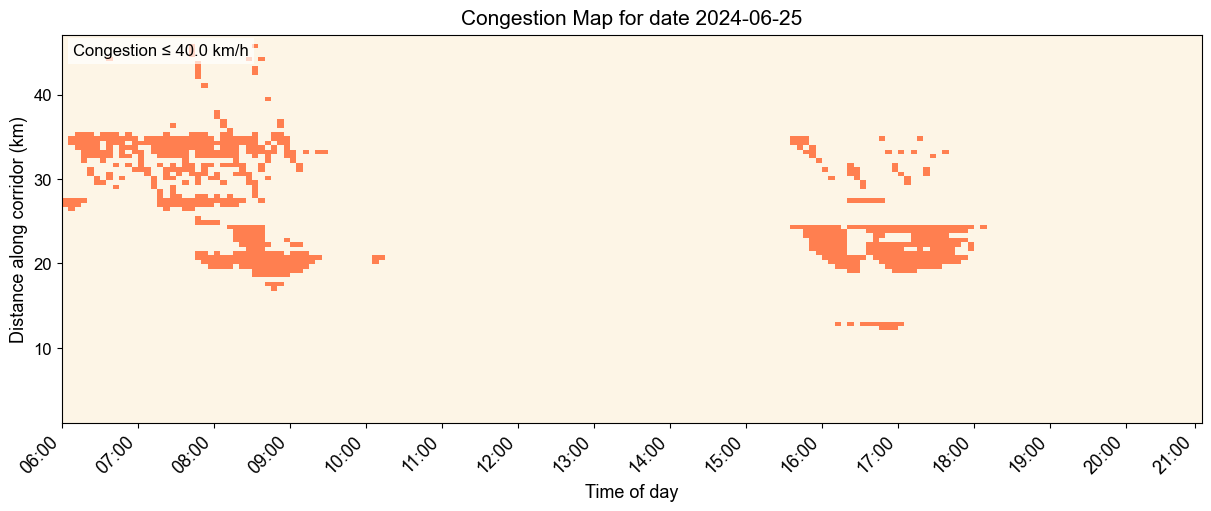

In [351]:
# ===============================
# Highlight Congestion Areas Only
# ===============================

DAYS = [1]              # choose days by index from `day_table`
TIME_START, TIME_END = "06:00", "20:59"
ABS_THRESHOLD = 40.0    # absolute threshold [km/h], or None
REL_QUANTILE = 0.25     # if abs is None, use relative (lowest 25%)
FLIP_DISTANCE = True    # match contour plot convention

from matplotlib.colors import ListedColormap

def congestion_mask(Z, abs_thr=None, quantile=None):
    V = Z.to_numpy()
    if abs_thr is not None:
        thr = abs_thr
    elif quantile is not None:
        thr = np.nanquantile(V, quantile)
    else:
        raise ValueError("Must set abs_thr or quantile")
    return (V <= thr), thr

def build_speed_grid(spd: pd.DataFrame):
    """Return pivot table for one day's data, restricted to TIME_START–TIME_END."""
    if spd.empty:
        return None, None, None
    Z = spd.pivot_table(index="time", columns="km", values="speed_kmh", aggfunc="mean").sort_index()
    Z = Z.between_time(TIME_START, TIME_END)
    return Z, Z.columns.to_numpy(float), Z.index

def plot_congestion_only(Z, km_vals, t_vals, title,
                         abs_thr=ABS_THRESHOLD,
                         rel_q=REL_QUANTILE,
                         cong_color="coral", neutral_color="oldlace",
                         flip_distance=FLIP_DISTANCE):
    """
    Show congestion cells filled with one color; non-congested cells as neutral.
    """
    V = Z.to_numpy()
    cong, thr = (congestion_mask(Z, abs_thr=abs_thr)
                 if abs_thr is not None else
                 congestion_mask(Z, quantile=rel_q))

    mask = cong.astype(int).T
    fig, ax = plt.subplots(1, 1, figsize=(12, 5), constrained_layout=True)
    cmap = ListedColormap([neutral_color, cong_color])

    origin = "upper" if flip_distance else "lower"
    im = ax.imshow(mask, aspect="auto", origin=origin, cmap=cmap,
                   extent=[0, V.shape[0], km_vals.min(), km_vals.max()])

    ax.set_ylabel("Distance along corridor (km)")
    xt, xl = hour_ticks(t_vals)
    ax.set_xticks(xt)
    ax.set_xticklabels(xl, rotation=45, ha="right")
    ax.set_xlabel("Time of day")

    ax.set_title(title, pad=8)
    ax.text(0.01, 0.98, f"Congestion ≤ {thr:.1f} km/h",
            transform=ax.transAxes, ha="left", va="top",
            fontsize=12, bbox=dict(facecolor="white", alpha=0.7, lw=0))
    plt.show()

# ======= Main loop =======
for i in DAYS:
    if (i < 0) or (i >= len(day_table)):
        print(f"Skip index {i}: out of range (0..{len(day_table)-1}).")
        continue
    date_i = day_table.loc[i, "date"]
    print(f"\nSelected date [{i}] {date_i}")

    spd = load_speed_for_day(i)
    if spd.empty:
        print(f"No speed data for {date_i}")
        continue
    Z, km_vals, t_vals = build_speed_grid(spd)
    if Z is None:
        print(f"No grid data for {date_i}")
        continue
    plot_congestion_only(Z, km_vals, t_vals,
                         title=f"Congestion Map for date {date_i}")



---
## 5. Shockwave Theory (~10 min)
### *Task* 
- Use contour plots to estimate propagation speed of congestion fronts.

### *Questions*
- Pick two times during a breakdown and locate the congestion front. What is the estimated propagation speed?
- Is the shockwave **upstream** (negative, typical) or **downstream**?
- Does the speed change between the onset and the recovery phase? Why might that be?

> **🛠️ _Parameters:** change `DAY` to choose a date, `TIME_A` and `TIME_B` to choose start and end time of the congestion, `KM_RANGE` to decide the location of the shockwave cell.


Date 2024-06-25
Front 15:40: km=22.82, 16:20: km=19.45
Δx=-3.37 km, Δt=40.00 min → w=-5.05 km/h (upstream)


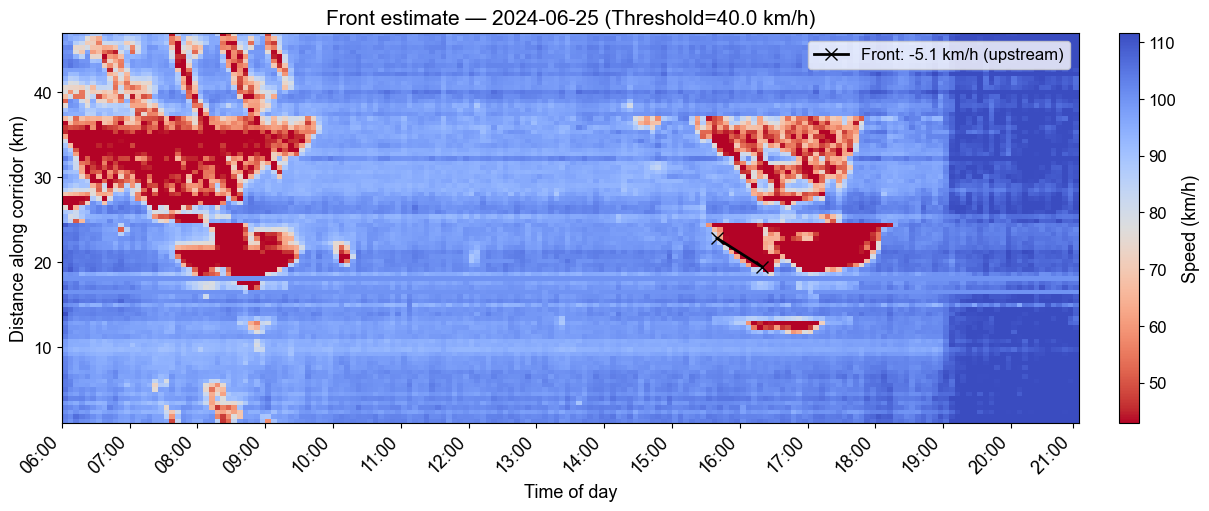

In [352]:
# ======================================================
# Propagation speed from the heatmap grid + plot overlay
# ======================================================

DAY        = 1
THRESHOLD  = 40.0
TIME_A     = "15:40"
TIME_B     = "16:20"
KM_RANGE   = (19.0, 26.0)
CMAP       = "coolwarm_r"
FLIP_DISTANCE = True

# --- helpers ---
def _time_to_index(t_vals: pd.DatetimeIndex, hhmm: str) -> int:
    target = pd.Timestamp(f"{t_vals[0].date()} {hhmm}")
    if target < t_vals[0]:  target = t_vals[0]
    if target > t_vals[-1]: target = t_vals[-1]
    return int(np.argmin(np.abs((t_vals - target).total_seconds())))

def _front_km_at_time(v_along_km, km_vals, thr, km_range=None):
    v = np.asarray(v_along_km).astype(float)
    k = np.asarray(km_vals).astype(float)

    if km_range is not None:
        km_min, km_max = km_range
        mask = (k >= km_min) & (k <= km_max)
        if not mask.any():
            return None
        v, k = v[mask], k[mask]

    if v.size == 0 or np.all(np.isnan(v)):
        return None

    d = v - thr
    valid = ~np.isnan(d)
    idxs = np.where(valid[:-1] & valid[1:] & (np.sign(d[:-1]) != np.sign(d[1:])))[0]
    if idxs.size > 0:
        i = int(idxs[0])
        denom = d[i+1] - d[i]
        if denom != 0:
            alpha = -d[i] / denom
            return float(k[i] + alpha * (k[i+1] - k[i]))
    j = int(np.nanargmin(np.abs(d)))
    return float(k[j])

# --- main compute ---
date_i = day_table.loc[DAY, "date"]
spd = load_speed_for_day(DAY)
speed = spd.copy()  # to reuse build_speed_grid_for_date
Z, km_vals, t_vals = build_speed_grid_for_date(date_i)
V = Z.to_numpy()
T, K = V.shape

ia = _time_to_index(t_vals, TIME_A)
ib = _time_to_index(t_vals, TIME_B)
kma = _front_km_at_time(V[ia, :], km_vals, THRESHOLD, km_range=KM_RANGE)
kmb = _front_km_at_time(V[ib, :], km_vals, THRESHOLD, km_range=KM_RANGE)

dt_min = (t_vals[ib] - t_vals[ia]).total_seconds() / 60.0
dx_km  = kmb - kma
w_kmh  = (dx_km / dt_min) * 60.0
direction = "upstream" if w_kmh < 0 else "downstream"

print(f"\nDate {date_i}")
print(f"Front {TIME_A}: km={kma:.2f}, {TIME_B}: km={kmb:.2f}")
print(f"Δx={dx_km:.2f} km, Δt={dt_min:.2f} min → w={w_kmh:.2f} km/h ({direction})")

# --- plot speed heatmap + front line ---
fig, ax = plt.subplots(1, 1, figsize=(12, 5), constrained_layout=True)

origin = "upper" if FLIP_DISTANCE else "lower"
im = ax.imshow(
    V.T, aspect="auto", cmap=CMAP,
    vmin=np.nanpercentile(V, 5), vmax=np.nanpercentile(V, 95),
    origin=origin, extent=[0, T, km_vals.min(), km_vals.max()]
)
cb = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cb.set_label("Speed (km/h)")

# overlay line showing propagation
ax.plot([ia, ib], [kma, kmb], "kx-", lw=2, ms=8,
        label=f"Front: {w_kmh:.1f} km/h ({direction})")
ax.legend(loc="upper right")

# cosmetics
ax.set_ylabel("Distance along corridor (km)")
xt, xl = hour_ticks(t_vals)
ax.set_xticks(xt)
ax.set_xticklabels(xl, rotation=45, ha="right")
ax.set_xlabel("Time of day")
ax.set_title(f"Front estimate — {date_i} (Threshold={THRESHOLD} km/h)")

plt.show()



---
## 6. Sensor Correlation & Lead/Lag (~10 min)
### *Tasks*
- Compute correlations between consecutive sensors.
- Explore lead/lag relationships to see how congestion propagates.
- Relate to the concept of information flow.

### *Questions*
- Are consecutive sensors highly correlated? Where does correlation drop?
- Do lags suggest **upstream** (negative) or **downstream** propagation?
- How do these results relate to your shockwave estimates and contour plots?

> **🛠️ _Parameters:** change `DAY` to choose a date, choose a `FEATURE` for analysis.


Selected [1] 2024-06-25 — feature: speed


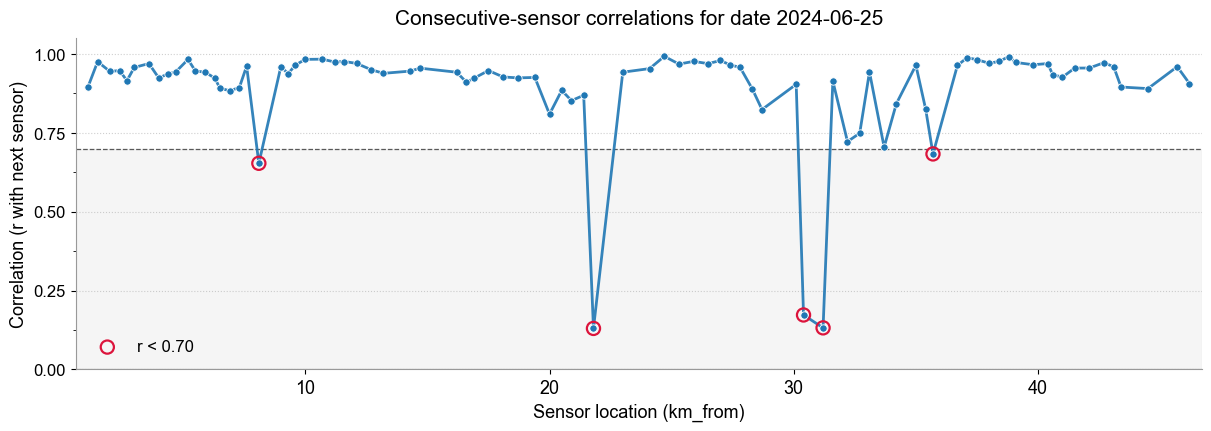

In [353]:
# =================================
# Sensor Agreement Along a Corridor
# =================================

DAY = 1                          # pick a date from day_table
FEATURE = "speed"                # toggle feature: "speed" | "flow"
TIME_START, TIME_END = "06:00", "20:59"
ROLL_MINUTES = None              # e.g. 15 for a 15-min rolling mean; or None
PRINT_HEAD = 10
MIN_OVERLAP = 6                  # require at least N overlapping points for a pair; set 0 to disable
ALERT_CUTOFF = 0.70              # highlight low-agreement segments in visuals

# ======= Load feature data for a given day =======
def load_feature_for_day(day_idx: int, feature: str) -> pd.DataFrame:
    """
    Returns tidy long-form df with columns: time, km, metric
    feature in {"speed","flow","occupancy"}.
    """
    p = day_table.loc[day_idx, "path"]

    if feature == "speed":
        wide = parse_matrix(p, r"Gebruikte\s+snelheden") 
        df = tidy(wide, "value")[["time","km","value"]]
        df = df.rename(columns={"value":"metric"})
        unit = "km/h"

    elif feature == "flow":
        wide = parse_matrix(p, r"Gebruikte\s+intensiteiten")    
        df = tidy(wide, "value")[["time","km","value"]]
        df = df.rename(columns={"value":"metric"})
        unit = "veh/h"

    else:
        raise ValueError("FEATURE must be one of: 'speed' or 'flow'.")

    df["time"] = pd.to_datetime(df["time"])
    df["km"] = df["km"].astype(float)
    df["metric"] = pd.to_numeric(df["metric"], errors="coerce")
    df.attrs["unit"] = unit
    return df

# ======= Build grid of the feature (time vs. distance) =======
def build_grid(df_long: pd.DataFrame) -> tuple[pd.DataFrame, np.ndarray, pd.DatetimeIndex, str]:
    """
    Pivot to a grid: rows=time (5-min), cols=km, values=metric.
    Restrict to TIME_START..TIME_END. Optionally smooth.
    """
    Z = (df_long
         .pivot_table(index="time", columns="km", values="metric", aggfunc="mean")
         .sort_index())
    Z = Z.between_time(TIME_START, TIME_END)

# Optional rolling mean smoothing
    if ROLL_MINUTES:
        if len(Z.index) >= 2:
            step_min = int((Z.index[1] - Z.index[0]).total_seconds() // 60)
        else:
            step_min = 5
        w = max(1, int(round(ROLL_MINUTES / step_min)))
        Z = Z.rolling(window=w, min_periods=max(1, w//2), center=True).mean()

    km_vals = Z.columns.to_numpy(float)
    t_vals  = Z.index
    unit    = df_long.attrs.get("unit", "")
    return Z, km_vals, t_vals, unit

# ======= Main: load data for the selected day =======
def _pearson(x: np.ndarray, y: np.ndarray) -> tuple[float, int]:
    """
    Pearson r that returns NaN if <3 points overlap or zero variance.
    Returns (r, n_overlap).
    """
    m = ~np.isnan(x) & ~np.isnan(y)
    n = int(m.sum())
    if n < 3:
        return np.nan, n
    xv, yv = x[m].astype(float), y[m].astype(float)
    dx, dy = xv - xv.mean(), yv - yv.mean()
    num = np.sum(dx * dy)
    den = np.sqrt(np.sum(dx * dx) * np.sum(dy * dy))
    if den == 0.0:
        return np.nan, n
    return float(num / den), n

# ======= Compute correlations between consecutive sensors =======
def consecutive_correlations(Z: pd.DataFrame) -> pd.DataFrame:
    """
    Pearson correlations between consecutive sensor columns (km_j, km_{j+1}),
    robust to NaNs and zero-variance series. Also returns n_pairs used.
    """
    V = Z.to_numpy()                          # (T, K)
    kms = Z.columns.to_numpy(float)
    corrs, n_pairs = [], []
    # loop over consecutive sensor pairs
    for j in range(len(kms) - 1):
        r, n = _pearson(V[:, j], V[:, j+1])
        corrs.append(r)
        n_pairs.append(n)
    out = pd.DataFrame({"km_from": kms[:-1], "km_to": kms[1:], "corr": corrs, "n_pairs": n_pairs})
    if MIN_OVERLAP and MIN_OVERLAP > 0:
        out.loc[out["n_pairs"] < MIN_OVERLAP, "corr"] = np.nan
    return out

# ======= Plotting helpers =======
def plot_corr_corridor(corr_df, title):
    CMAP = "RdYlBu_r"
    VMIN, VMAX = -1.0, 1.0

    # Build line segments and colors
    segs, colors = [], []
    for _, r in corr_df.dropna(subset=["corr"]).iterrows():
        segs.append([(r["km_from"], 0.0), (r["km_to"], 0.0)])
        colors.append(r["corr"])

# ======= Plot correlation along the corridor =======
    fig, ax = plt.subplots(1, 1, figsize=(12, 2.6), constrained_layout=True)
    if segs:
        lc = LineCollection(segs, cmap=CMAP, norm=Normalize(VMIN, VMAX), linewidths=10)
        lc.set_array(np.array(colors))
        ax.add_collection(lc)
        cbar = plt.colorbar(lc, ax=ax, fraction=0.046, pad=0.08)
        cbar.set_label("Pearson r")
    else:
        ax.text(0.5, 0.5, "No valid segment correlations", ha="center", va="center", transform=ax.transAxes)

    low = corr_df["corr"] < ALERT_CUTOFF
    if low.any():
        xs = 0.5 * (corr_df.loc[low, "km_from"].to_numpy() + corr_df.loc[low, "km_to"].to_numpy())
        ax.plot(xs, np.zeros_like(xs), "v", ms=7, color="black", label=f"corr<{ALERT_CUTOFF:.2f}")

    ax.set_xlim(corr_df["km_from"].min(), corr_df["km_to"].max())
    ax.set_ylim(-1, 1)
    ax.set_yticks([])
    ax.set_xlabel("Distance along corridor (km)")
    ax.set_title(title)
    if low.any():
        ax.legend(loc="upper right", frameon=True)
    plt.show()

# ======= Alternative lollipop plot of correlations =======
def plot_corr_lollipop(corr_df, title):
    CMAP = "RdYlBu_r"
    VMIN, VMAX = -1.0, 1.0

    df = corr_df.copy().reset_index(drop=True)
    x = df["km_from"].to_numpy()
    y = df["corr"].to_numpy()

    fig, ax = plt.subplots(1, 1, figsize=(12, 4), constrained_layout=True)
    for xi, yi in zip(x, y):
        if np.isnan(yi): continue
        ax.plot([xi, xi], [0, yi], lw=2, color="0.85")
    sc = ax.scatter(x[~np.isnan(y)], y[~np.isnan(y)], c=y[~np.isnan(y)],
                    cmap=CMAP, vmin=VMIN, vmax=VMAX, s=60, zorder=3, edgecolor="k", linewidth=0.5)

    # Highlight low correlations
    idx_low = np.where((~np.isnan(y)) & (y < ALERT_CUTOFF))[0]
    if idx_low.size > 0:
        ax.scatter(x[idx_low], y[idx_low], facecolors="none", edgecolors="k", s=180, linewidths=1.5, zorder=4)
    ax.axhline(0, color="k", lw=0.8)
    ax.axhline(ALERT_CUTOFF, color="tab:gray", lw=0.8, ls="--")
    ax.set_ylim(-1.05, 1.05)
    ax.set_xlabel("Sensor location (km_from)")
    ax.set_ylabel("Correlation with next sensor")
    ax.set_title(title)
    cbar = plt.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label("Pearson r")
    plt.show()

# ======= Main loop: load data for the selected day =======
if (DAY < 0) or (DAY >= len(day_table)):
    raise IndexError(f"DAY={DAY} out of range (0..{len(day_table)-1}).")

date_i = day_table.loc[DAY, "date"]
print(f"Selected [{DAY}] {date_i} — feature: {FEATURE}")

# Load, build grid, compute correlations
feat_df = load_feature_for_day(DAY, FEATURE)
Z, km_vals, t_vals, unit = build_grid(feat_df)

corr_df = consecutive_correlations(Z)
# print("First rows:")
# print(corr_df.head(PRINT_HEAD))

df = corr_df.copy().dropna(subset=["corr"]).reset_index(drop=True)
x = df["km_from"].to_numpy()
y = df["corr"].to_numpy()

# ======= Plot correlation along the corridor =======
fig, ax = plt.subplots(figsize=(12, 4.2), constrained_layout=True)
ax.axhspan(-1.0, ALERT_CUTOFF, color="0.85", alpha=0.25, zorder=0)
ax.axhline(0, color="0.25", lw=0.8, zorder=1)
ax.axhline(ALERT_CUTOFF, color="0.35", lw=0.9, ls="--", zorder=1)
ax.plot(x, y, lw=2.0, color="C0", alpha=0.9, zorder=2)
ax.scatter(x, y, s=28, color="C0", edgecolor="white", linewidth=0.6, zorder=3)

# Highlight low correlations
low = y < ALERT_CUTOFF
if np.any(low):
    ax.scatter(x[low], y[low], s=90, facecolors="none", edgecolors="crimson",
               linewidths=1.6, zorder=4, label=f"r < {ALERT_CUTOFF:.2f}")

ax.set_title(f"Consecutive-sensor correlations for date {date_i}", pad=10)
ax.set_xlabel("Sensor location (km_from)")
ax.set_ylabel("Correlation (r with next sensor)")
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_locator(MultipleLocator(0.25))
ax.yaxis.set_minor_locator(MultipleLocator(0.125))
ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
ax.set_xlim(x.min() - 0.5, x.max() + 0.5)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
for spine in ("left", "bottom"):
    ax.spines[spine].set_color("0.6")
ax.grid(True, which="major", axis="y", linestyle=":", linewidth=0.8, alpha=0.6)

if np.any(low):
    ax.legend(frameon=False, loc="lower left")

plt.show()


Selected [1] 2024-06-25 — feature: speed
Lead/lag results (first rows):
   base_km   km  Δx_km  best_lag_min  r_at_lag  prop_speed_kmh
0     35.0  1.1  -33.9    -25.154973  0.256480       80.858764
1     35.0  1.5  -33.5    -20.889396  0.197150       96.221068
2     35.0  2.0  -33.0    -19.960325  0.187287       99.196780
3     35.0  2.4  -32.6    -19.206426  0.164363      101.840915
4     35.0  2.7  -32.3           NaN  0.148177             NaN
5     35.0  3.0  -32.0    -16.549395  0.162459      116.016323
6     35.0  3.6  -31.4    -16.493055  0.150227      114.229897
7     35.0  4.0  -31.0    -17.767375  0.158182      104.686260


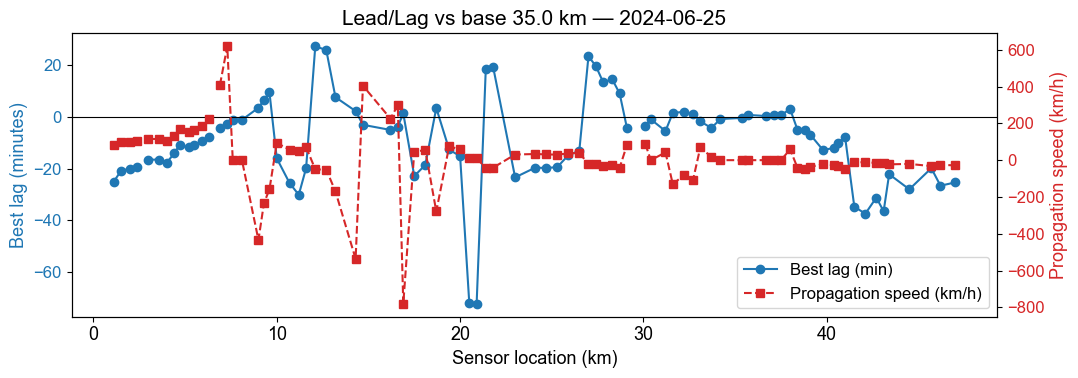

In [354]:
# ===================================================
# Cross-Correlation Analysis — Fixed Base Detector
# ===================================================

DAY = 1                    # pick a date from day_table
FEATURE = "speed"          # "speed" | "flow"
TIME_START, TIME_END = "06:00", "20:59"
MAX_LAG_MIN   = 90         # search window for lag (+/- minutes)
MIN_OVERLAP   = 8         # min overlapping samples per lag
MIN_ABS_R     = 0.15       # discard best lags with weak |correlation|
BASE_KM       = 35.0       # base detector location (choose near middle)
TINY_LAG_FRACTION = 0.25   # treat |lag| < 0.25 * dt as synchronous → speed 0
PRINT_HEAD    = 8          # show first rows

# ======= Load & grid the data =======
date_i = day_table.loc[DAY, "date"]
print(f"Selected [{DAY}] {date_i} — feature: {FEATURE}")

feat_df = load_feature_for_day(DAY, FEATURE)
Z, km_vals, t_vals, unit = build_grid(feat_df)

if len(t_vals) < 2:
    raise RuntimeError("Not enough time points to compute cross-correlation.")

dt_min = (t_vals[1] - t_vals[0]).total_seconds() / 60.0
max_lag_steps = int(np.floor(MAX_LAG_MIN / dt_min))

# ======= Cross-correlation helpers =======
def xcorr_curve(x: np.ndarray, y: np.ndarray, max_lag_steps: int, min_overlap: int):
    """Cross-correlation curve: lags in steps, Pearson r at each lag."""
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    L = max_lag_steps
    lags = np.arange(-L, L+1, dtype=int)
    rvals = np.full_like(lags, np.nan, dtype=float)

    for idx, lag in enumerate(lags):
        if lag >= 0:
            xs = x[:len(x)-lag]
            ys = y[lag:]
        else:
            xs = x[-lag:]
            ys = y[:len(y)+lag]

        m = ~np.isnan(xs) & ~np.isnan(ys)
        if m.sum() < min_overlap:
            continue
        xv, yv = xs[m], ys[m]
        dx, dy = xv - xv.mean(), yv - yv.mean()
        denom = np.sqrt((dx*dx).sum() * (dy*dy).sum())
        if denom == 0.0:
            continue
        rvals[idx] = (dx*dy).sum() / denom

    return lags, rvals

def best_lag_from_curve(lags_steps, rvals):
    """Pick lag with max |r|; quadratic interpolation if possible."""
    if np.all(np.isnan(rvals)):
        return np.nan, np.nan
    i = int(np.nanargmax(np.abs(rvals)))
    r0 = rvals[i]; lag0 = float(lags_steps[i])

    # optional quadratic refinement
    if 0 < i < len(rvals)-1 and np.isfinite(rvals[i-1]) and np.isfinite(rvals[i+1]):
        rm, rp = rvals[i-1], rvals[i+1]
        denom = (rm - 2*r0 + rp)
        if denom != 0:
            delta = 0.5 * (rm - rp) / denom
            return lag0 + float(delta), float(r0)

    return lag0, float(r0)

# ======= Analysis: base vs all others =======
# pick closest detector to BASE_KM
base_idx = int(np.argmin(np.abs(km_vals - BASE_KM)))
base_km  = float(km_vals[base_idx])
x_series = Z.iloc[:, base_idx].to_numpy()

rows = []
for j, km in enumerate(km_vals):
    if j == base_idx:
        continue
    y_series = Z.iloc[:, j].to_numpy()
    lags_s, r_lag = xcorr_curve(x_series, y_series, max_lag_steps, MIN_OVERLAP)
    lag_steps_f, r_best = best_lag_from_curve(lags_s, r_lag)

    if np.isnan(lag_steps_f) or (np.abs(r_best) < MIN_ABS_R):
        lag_min = np.nan
        speed_kmh = np.nan
    else:
        lag_min = lag_steps_f * dt_min
        dx_km = float(km - base_km)
        if abs(lag_min) < TINY_LAG_FRACTION * dt_min:
            speed_kmh = 0.0
        else:
            speed_kmh = dx_km / (lag_min/60.0)  # km per hour

    rows.append({
        "base_km": base_km,
        "km": km,
        "Δx_km": float(km - base_km),
        "best_lag_min": lag_min,
        "r_at_lag": r_best,
        "prop_speed_kmh": speed_kmh
    })

lag_df = pd.DataFrame(rows).sort_values("km").reset_index(drop=True)

print("Lead/lag results (first rows):")
print(lag_df.head(PRINT_HEAD))

# ======= Visualization =======
fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.plot(lag_df["km"], lag_df["best_lag_min"], "o-", color="tab:blue", label="Best lag (min)")
ax1.axhline(0, color="k", lw=0.8)
ax1.set_xlabel("Sensor location (km)")
ax1.set_ylabel("Best lag (minutes)", color="tab:blue")
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.set_title(f"Lead/Lag vs base {base_km:.1f} km — {date_i}")

ax2 = ax1.twinx()
ax2.plot(lag_df["km"], lag_df["prop_speed_kmh"], "s--", color="tab:red", label="Propagation speed (km/h)")
ax2.set_ylabel("Propagation speed (km/h)", color="tab:red")
ax2.tick_params(axis='y', labelcolor='tab:red')

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax2.legend(h1+h2, l1+l2, loc="lower right")

plt.tight_layout()
plt.show()


### 🔎 Interpreting Lead–Lag Correlations

When we compute the **cross-correlation** between a base detector (at position *x*) and another detector (at position *y*), the **lag that maximizes correlation** can be interpreted in terms of **traffic propagation**.


#### 📐 Expected lags from traffic theory

- **Shockwave propagation (congestion waves):**

  $$
  \Delta t = \frac{y - x}{w}
  $$

  where  
  - $(y - x)$ = distance between detectors (km)  
  - $w$ = shockwave speed (typically negative, e.g. –20 km/h)


- **Free-flow propagation:**

  $$
  \Delta t = \frac{x - u}{v_0}
  $$

  where  
  - $(x - u)$ = distance from upstream location $u$ to base detector $x$  
  - $v_0$ = free-flow speed (e.g. ~100 km/h)


#### 📊 How to interpret the results

- **Negative lags for upstream sensors**  
  → Matches $\tfrac{y-x}{w}$ with $w \approx -20$ km/h  
  → Indicates **congestion waves propagating backward**.

- **Small positive lags for downstream sensors**  
  → Matches $\tfrac{x-u}{v_0}$ with $v_0 \approx 100$ km/h  
  → Indicates **free-flow information moving forward**.

- **Outliers (e.g., ±300 km/h)**  
  → These are **not physical** but **numerical artifacts**, often caused by:  
    - weak correlations (low $|r|$)  
    - very small lag values  
  → Mitigated by applying robustness filters:  
    - minimum lag thresholds  
    - maximum speed caps  
    - minimum correlation strength


✅ **In summary:**  
- Cross-correlation finds the **lag of maximum agreement**.  
- That lag can be mapped to a **propagation speed**.  
- Comparing with theory ($w, v_0$) helps us distinguish between:  
  - **Shockwaves (congestion, backward)**  
  - **Free-flow propagation (forward)**  


### ❓ Question
- How would you design a method to **detect and handle outliers** in lead–lag analysis?  
  - Should we filter them based on correlation strength?  
  - Should we apply thresholds on plausible speeds?  
  - Or could we combine both approaches?

- Think about the trade-off:  
  - Filtering too much might remove useful signals.  
  - Filtering too little might keep unrealistic values.  


---
## 7. Incident integration (~10 min)
### *Tasks*
- Overlay incident records (e.g., accidents, broken-down vehicles) on your speed contour plots.
- Compare incident characteristics with observed traffic effects.
- Discuss whether similar disruptions could be detected without incident data, purely from the sensors.

### *Questions*
- Do incidents line up with the start of congestion, or do they happen after congestion has already formed?
- Do different incident types (accident vs. breakdown) show different traffic signatures?
- If you only had the sensor data, what features (e.g., sudden speed drop, queue buildup) could help you detect an incident automatically?
- How could integrating incident data improve your shockwave analysis or propagation speed estimates?

> **🛠️ _Parameters:** 
- choose `DAY`, choose a `FEATURE` for analysis; 
- adjust the `TIME_WINDOW` and `KM_RANGE` to focus on an event of interest; 
- Pick incident TYPES of interest (e.g., `ACCIDENT`, `BROKEN_DOWN_VEHICLE`) in visualization.

In [ ]:
# Load the CSV file
df = pd.read_csv("/incidents_A4&A13_June24&25.csv")
ROAD = "A4"                # road
DIRECTION = "L"            # direction
DATE = "2025-06-25"        # choose a date
TZ = "Europe/Amsterdam"
Y_MIN, Y_MAX = 1.1, 47.0
X_START, X_END = "06:00", "21:00"  # daily time window
WANTED = {"ACCIDENT", "BROKEN_DOWN_VEHICLE"}

# ====================
# Show the first 5 rows
print("First 5 rows of the dataset:")
print(df.head())

# Show general info (columns, types, null counts)
print("\nDataset Info:")
print(df.info())

# Show basic statistics (for numeric columns)
print("\nBasic Statistics:")
print(df.describe())

# Check shape (rows, columns)
print("\nDataset Shape (rows, columns):")
print(df.shape)

# See column names
print("\nColumn Names:")
print(df.columns)

/Users/cielyao/opt/anaconda3/py311/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:57: RuntimeWarning: overflow encountered in multiply
  return bound(*args, **kwds)



A4 dir L — 2024-06-25 06:00–21:00 | incidents: 25
                                        id               _type richting       start_time         end_time  start_km  end_km
                            RWS03_272078_1 BROKEN_DOWN_VEHICLE        L 2024-06-25 06:30 2024-06-25 06:47       0.2     0.2
                            RWS03_272083_1 BROKEN_DOWN_VEHICLE        L 2024-06-25 06:42 2024-06-25 07:08       1.8     1.8
                            RWS03_272117_1 BROKEN_DOWN_VEHICLE        L 2024-06-25 07:37 2024-06-25 08:02       5.2     5.2
                        NLRWS_0004160789_1 BROKEN_DOWN_VEHICLE        L 2024-06-25 07:38 2024-06-25 07:41       5.2     5.2
                            RWS03_272129_1            ACCIDENT        L 2024-06-25 07:56 2024-06-25 08:22       1.2     1.2
                            RWS03_272162_1 BROKEN_DOWN_VEHICLE        L 2024-06-25 08:42 2024-06-25 09:06       2.5     2.5
                            RWS03_272218_1 BROKEN_DOWN_VEHICLE        L 2024-06-2

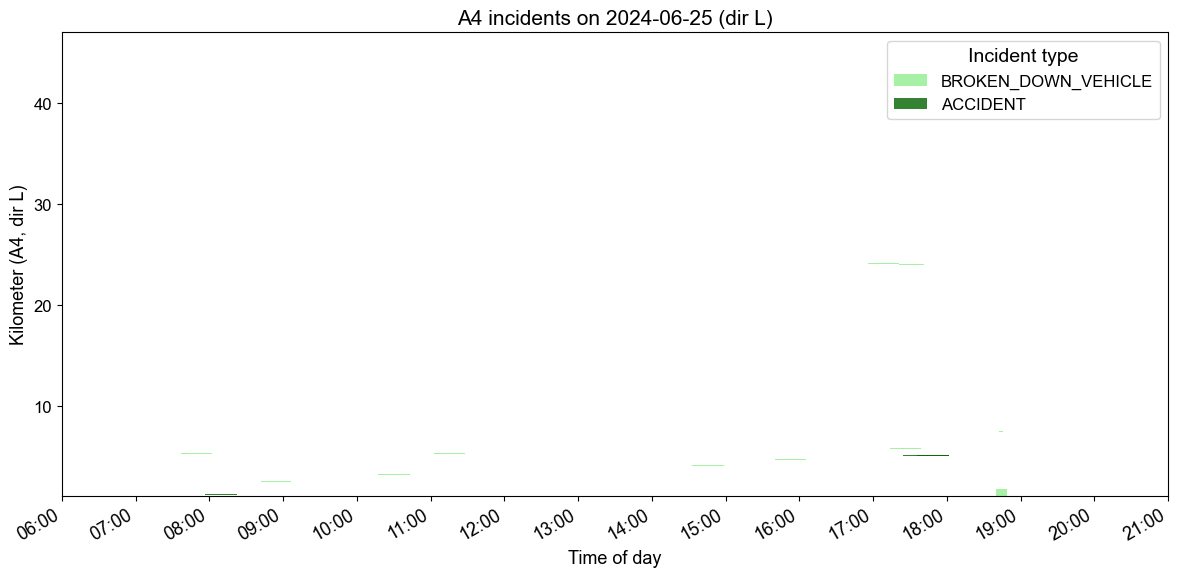

In [366]:
# ====== LOAD DATA ======
df = pd.read_csv("/Users/cielyao/Library/CloudStorage/OneDrive-DelftUniversityofTechnology/Documents/TUDelft/POSTDOC/Data/incidents_A4&A13_June24&25.csv")

# ====== CONFIG ======
ROAD = "A4"
DIRECTION = "L"
DATE = "2024-06-25"         # your date
TZ = "Europe/Amsterdam"
X_START, X_END = 6, 21      # 06:00–21:00
Y_MIN, Y_MAX = 1.1, 47.0
WANTED_TYPES = {"ACCIDENT", "BROKEN_DOWN_VEHICLE"}
# ====================

def parse_excel_serial(series, tz=TZ):
    """Excel serial (days since 1899-12-30) -> tz-aware datetimes."""
    origin = pd.Timestamp("1899-12-30")
    dt = origin + pd.to_timedelta(series, unit="D")
    return dt.dt.tz_localize(tz, ambiguous="NaT", nonexistent="NaT")

def normalize_type(val):
    t = (str(val) if pd.notnull(val) else "").upper().replace("-", "_")
    if t in {"VEHICLE_OBSTRUCTION","VEHICLE_OBSTACLE"}:
        return "BROKEN_DOWN_VEHICLE"
    return t

def km_start_end(row):
    p_hm = row.get("vild_primair_hectometer")
    s_hm = row.get("vild_secundair_hectometer")
    dist_m = row.get("vild_afstand_tot_primaire_locatie")
    p_km = p_hm/10 if pd.notnull(p_hm) else np.nan
    s_km = s_hm/10 if pd.notnull(s_hm) else np.nan
    if pd.notnull(p_km) and pd.notnull(s_km):
        return min(p_km, s_km), max(p_km, s_km)
    if pd.notnull(p_km) and pd.notnull(dist_m):
        return min(p_km, p_km + dist_m/1000), max(p_km, p_km + dist_m/1000)
    if pd.notnull(p_km): return p_km, p_km
    if pd.notnull(s_km): return s_km, s_km
    return np.nan, np.nan

# ---- 1) Load & base filters
INCIDENT_COL = "type" if "type" in df.columns else "gedetailleerd_type"
df["_type"] = df[INCIDENT_COL].map(normalize_type)

is_road = ((df.get("vild_primair_wegnummer","").astype(str).str.upper()==ROAD) |
           (df.get("vild_secundair_wegnummer","").astype(str).str.upper()==ROAD))
is_dir  = df.get("vild_primair_richting","").astype(str).str.upper()==DIRECTION
df = df[is_road & is_dir & df["_type"].isin(WANTED_TYPES)].copy()

# ---- 2) Parse the real times (Excel serials)
df["_start_dt"] = parse_excel_serial(df["situatie_aangemaakt_tijd"])
df["_end_dt"]   = parse_excel_serial(df["eindtijd"]) if "eindtijd" in df.columns else pd.NaT

# ---- 3) Compute km start/end for each row
df[["_km_start","_km_end"]] = df.apply(km_start_end, axis=1, result_type="expand")

# ---- 4) Keep only rows whose START is inside the chosen day & window
day = pd.Timestamp(DATE, tz=TZ)
day_start = day.replace(hour=X_START, minute=0, second=0)
day_end   = day.replace(hour=X_END,   minute=0, second=0)
df_day = df[(df["_start_dt"] >= day_start) & (df["_start_dt"] <= day_end)].copy()

# ---- 5) Collapse duplicates: one row per id
collapsed = (
    df_day
    .groupby("id", as_index=False)
    .agg(
        _type=("_type", "first"),
        richting=("vild_primair_richting","first"),
        start_dt=("_start_dt","min"),
        end_dt=("_end_dt","max"),
        start_km=("_km_start","min"),
        end_km=("_km_end","max"),
    )
)

# ---- 6) Summary table
summary = collapsed.assign(
    start_time=collapsed["start_dt"].dt.strftime("%Y-%m-%d %H:%M"),
    end_time=collapsed["end_dt"].dt.strftime("%Y-%m-%d %H:%M").fillna("open"),
    start_km=collapsed["start_km"].round(1),
    end_km=collapsed["end_km"].round(1),
)[["id","_type","richting","start_time","end_time","start_km","end_km"]]\
 .sort_values(["start_time","id"]).reset_index(drop=True)

print(f"\n{ROAD} dir {DIRECTION} — {DATE} {X_START:02d}:00–{X_END:02d}:00 | incidents: {len(summary)}")
print(summary.to_string(index=False))

# ---- 6b) Optional filter: choose which incident types to visualize
    #   change this line:
    #   {"ACCIDENT"} → only accidents
    #   {"BROKEN_DOWN_VEHICLE"} → only breakdowns
    #   {"ACCIDENT","BROKEN_DOWN_VEHICLE"} → both
VISUALIZE_TYPES = {"ACCIDENT", "BROKEN_DOWN_VEHICLE"}
collapsed_vis = collapsed[collapsed["_type"].isin(VISUALIZE_TYPES)].copy()

# ---- 7) Visualization: draw rectangles (duration × km span)
plt.figure(figsize=(12,6))
ax = plt.gca()

colors = {"ACCIDENT":"darkgreen", "BROKEN_DOWN_VEHICLE":"lightgreen"}
for _, row in collapsed_vis.iterrows():
    if pd.isna(row["start_dt"]): 
        continue
    x0 = mdates.date2num(row["start_dt"])  # convert to float
    x1 = mdates.date2num(row["end_dt"]) if pd.notna(row["end_dt"]) else mdates.date2num(day_end)
    y0 = row["start_km"]
    y1 = row["end_km"] if pd.notna(row["end_km"]) else row["start_km"]

    width  = x1 - x0
    height = (y1 - y0) if (y1 > y0) else 0.05

    rect = Rectangle((x0, y0), width, height,
                     facecolor=colors.get(row["_type"], "gray"),
                     alpha=0.8,
                     label=row["_type"])
    ax.add_patch(rect)

plt.ylim(Y_MIN, Y_MAX)
plt.xlim(day_start, day_end)
plt.xlabel("Time of day")
plt.ylabel(f"Kilometer ({ROAD}, dir {DIRECTION})")
plt.title(f"{ROAD} incidents on {DATE} (dir {DIRECTION})")

# Format x-axis as time
ax.xaxis_date()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=TZ))
ax.xaxis.set_major_locator(mdates.HourLocator(interval=1))
plt.gcf().autofmt_xdate()

# Avoid duplicate legend entries
handles, labels = ax.get_legend_handles_labels()
bylabel = dict(zip(labels, handles))
plt.legend(bylabel.values(), bylabel.keys(), title="Incident type")

plt.tight_layout()
plt.show()



Selected date [1] 2024-06-25


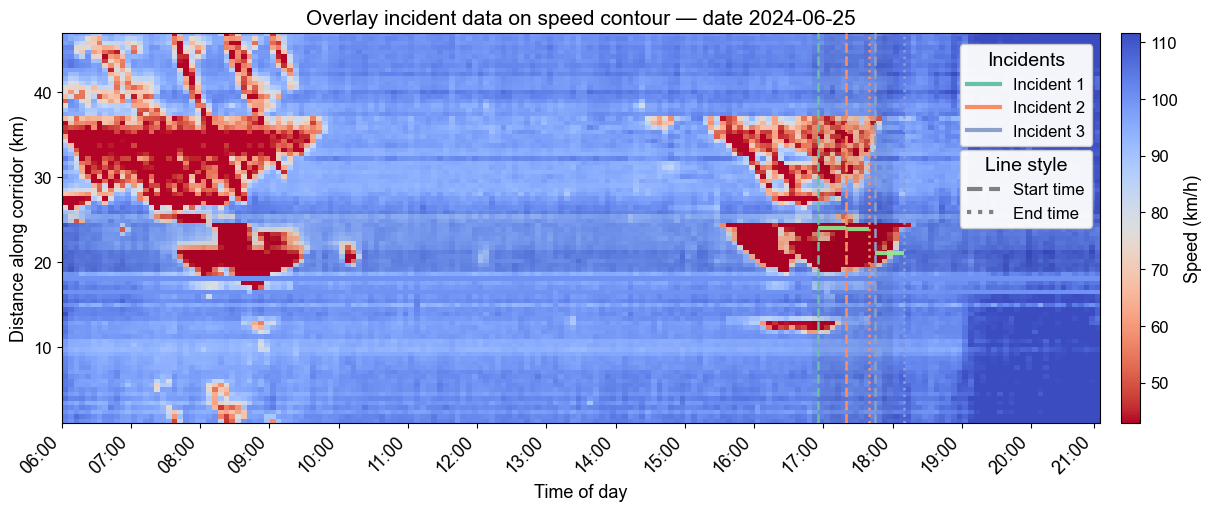

Incidents overlapping 16:50–18:00, km 19.0–26.0: 3
            id               _type richting       start_time         end_time  start_km  end_km
RWS03_272596_1 BROKEN_DOWN_VEHICLE        L 2024-06-25 16:56 2024-06-25 17:21      24.1    24.1
RWS03_272643_1 BROKEN_DOWN_VEHICLE        L 2024-06-25 17:21 2024-06-25 17:41      24.0    24.0
RWS03_272676_1 BROKEN_DOWN_VEHICLE        L 2024-06-25 17:46 2024-06-25 18:12      21.1    21.1


In [369]:
# ---------- CONFIG ----------
DAYS = [1]                                # pick a date from day_table
TIME_START, TIME_END = "06:00", "20:59"   # daily time window
TIME_A   = "16:50"                        # selection start
TIME_B   = "18:00"                        # selection end
KM_RANGE = (19.0, 26.0)                   # selection km range
SPEED_CMAP = "coolwarm_r"
FLIP_DISTANCE = True

# Palette to color incidents (same color for start/end of an incident)
INCIDENT_PALETTE = list(plt.cm.Set2.colors)   # change to Set2, Dark2, tab10, etc.

# ---------- INCIDENT HELPERS (unchanged plotting; just loading fixed) ----------
def parse_excel_serial(series, tz=TZ):
    origin = pd.Timestamp("1899-12-30")
    dt = origin + pd.to_timedelta(series, unit="D")
    return dt.dt.tz_localize(tz, ambiguous="NaT", nonexistent="NaT")

def normalize_type(val):
    t = (str(val) if pd.notnull(val) else "").upper().replace("-", "_")
    if t in {"VEHICLE_OBSTRUCTION","VEHICLE_OBSTACLE"}:
        return "BROKEN_DOWN_VEHICLE"
    return t

def km_start_end(row):
    p_hm = row.get("vild_primair_hectometer")
    s_hm = row.get("vild_secundair_hectometer")
    dist_m = row.get("vild_afstand_tot_primaire_locatie")
    p_km = p_hm/10 if pd.notnull(p_hm) else np.nan
    s_km = s_hm/10 if pd.notnull(s_hm) else np.nan
    if pd.notnull(p_km) and pd.notnull(s_km):
        return min(p_km, s_km), max(p_km, s_km)
    if pd.notnull(p_km) and pd.notnull(dist_m):
        return min(p_km, p_km + dist_m/1000), max(p_km, p_km + dist_m/1000)
    if pd.notnull(p_km): return p_km, p_km
    if pd.notnull(s_km): return s_km, s_km
    return np.nan, np.nan

def load_incidents_for_date(date_ts: pd.Timestamp, incidents_df: pd.DataFrame) -> pd.DataFrame:
    """
    Use the already-loaded incidents DataFrame `incidents_df` (== your `df`).
    Normalize and collapse to one row per incident id for the given local calendar date.
    """
    df_in = incidents_df.copy()

    INCIDENT_COL = "type" if "type" in df_in.columns else "gedetailleerd_type"
    df_in["_type"] = df_in[INCIDENT_COL].map(normalize_type)

    is_road = ((df_in.get("vild_primair_wegnummer","").astype(str).str.upper()==ROAD) |
               (df_in.get("vild_secundair_wegnummer","").astype(str).str.upper()==ROAD))
    is_dir  = df_in.get("vild_primair_richting","").astype(str).str.upper()==DIRECTION
    df_in = df_in[is_road & is_dir & df_in["_type"].isin(WANTED_TYPES)].copy()

    df_in["_start_dt"] = parse_excel_serial(df_in["situatie_aangemaakt_tijd"])
    df_in["_end_dt"]   = parse_excel_serial(df_in["eindtijd"]) if "eindtijd" in df_in.columns else pd.NaT
    df_in[["_km_start","_km_end"]] = df_in.apply(km_start_end, axis=1, result_type="expand")

    # same local calendar day as date_ts
    local_date = date_ts.tz_localize(TZ) if date_ts.tzinfo is None else date_ts
    local_date = local_date.tz_convert(TZ)
    day_start = local_date.normalize()
    day_end   = day_start + pd.Timedelta(days=1)
    df_in = df_in[(df_in["_start_dt"] >= day_start) & (df_in["_start_dt"] < day_end)].copy()

    collapsed = (
        df_in.groupby("id", as_index=False)
             .agg(
                 _type=("_type", "first"),
                 richting=("vild_primair_richting","first"),
                 start_dt=("_start_dt","min"),
                 end_dt=("_end_dt","max"),
                 start_km=("_km_start","min"),
                 end_km=("_km_end","max"),
             )
             .sort_values("start_dt")
             .reset_index(drop=True)
    )
    return collapsed

# ---------- MAP INCIDENT TIMES TO HEATMAP X-AXIS ----------
def _time_to_index(t_vals: pd.DatetimeIndex, hhmm: str) -> int:
    target = pd.Timestamp(f"{t_vals[0].date()} {hhmm}")
    target = min(max(target, t_vals[0]), t_vals[-1])
    return int(np.argmin(np.abs((t_vals - target).total_seconds())))

def _dt_to_index(t_vals: pd.DatetimeIndex, dt: pd.Timestamp, tz=TZ) -> int | None:
    if pd.isna(dt): return None
    dt_local = dt.tz_convert(tz)
    hhmmss = dt_local.strftime("%H:%M:%S")
    target = pd.Timestamp(f"{t_vals[0].date()} {hhmmss}")
    target = min(max(target, t_vals[0]), t_vals[-1])
    return int(np.argmin(np.abs((t_vals - target).total_seconds())))

# ---------- MAIN ----------
for i in DAYS:
    if (i < 0) or (i >= len(day_table)):
        print(f"Skip index {i}: out of range.")
        continue

    date_i = day_table.loc[i, "date"]
    print(f"\nSelected date [{i}] {date_i}")

    # -- speed heatmap --
    spd = load_speed_for_day(i)
    if spd.empty:
        print(f"No speed data for {date_i}")
        continue
    Z, km_vals, t_vals = build_speed_grid_for_date(date_i)
    if Z is None or Z.empty:
        print(f"No data in {TIME_START}-{TIME_END} for {date_i}")
        continue

    V = Z.to_numpy()
    T = V.shape[0]
    vmin, vmax = np.nanpercentile(V, 5), np.nanpercentile(V, 95)

    fig, ax = plt.subplots(1, 1, figsize=(12, 5), constrained_layout=True)
    origin = "upper" if FLIP_DISTANCE else "lower"
    im = ax.imshow(V.T, aspect="auto", cmap=SPEED_CMAP, vmin=vmin, vmax=vmax,
                   origin=origin, extent=[0, T, km_vals.min(), km_vals.max()])

    # axes labels/ticks
    ax.set_ylabel("Distance along corridor (km)")
    xt, xl = hour_ticks(t_vals); ax.set_xticks(xt); ax.set_xticklabels(xl, rotation=45, ha="right")
    ax.set_xlabel("Time of day")
    ax.set_title(f"Overlay incident data on speed contour — date {date_i}")

    # selection guides (optional)
    ia = _time_to_index(t_vals, TIME_A)
    ib = _time_to_index(t_vals, TIME_B)
    km_min, km_max = KM_RANGE
    ax.axvspan(ia, ib, color="k", alpha=0.06, lw=0)
    ax.axhspan(km_min, km_max, color="k", alpha=0.05, lw=0)

    # -- load & filter incidents for this date (from preloaded df) --
    inc = load_incidents_for_date(pd.Timestamp(str(date_i)), incidents_df=df)
    if inc.empty:
        cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04); cb.set_label("Speed (km/h)")
        plt.show(); print("No incidents on this date."); 
        continue

    # overlap with window (time + km)
    t0 = pd.Timestamp(f"{date_i} {TIME_A}", tz=TZ)
    t1 = pd.Timestamp(f"{date_i} {TIME_B}", tz=TZ)
    def _overlaps_window(row):
        t_start = row["start_dt"]
        t_end   = row["end_dt"] if pd.notna(row["end_dt"]) else t1
        time_ok = (t_start <= t1) and (t_end >= t0)
        s, e = row["start_km"], row["end_km"] if pd.notna(row["end_km"]) else row["start_km"]
        lo, hi = (min(s, e), max(s, e))
        km_ok = (lo <= km_max) and (hi >= km_min)
        return bool(time_ok and km_ok)

    # (bugfix) create inc_sel first, then proceed — plotting code unchanged
    inc_sel = inc[inc.apply(_overlaps_window, axis=1)].copy()
    inc_sel = inc_sel.sort_values("start_dt").reset_index(drop=True)
    inc_sel["inc_no"] = np.arange(1, len(inc_sel) + 1)

    # palette for start/end verticals (incident-wise unique)
    colors_inc = [INCIDENT_PALETTE[i % len(INCIDENT_PALETTE)] for i in range(len(inc_sel))]
    type_colors = {"ACCIDENT": "darkgreen", "BROKEN_DOWN_VEHICLE": "lightgreen"}

    color_handles = []
    EPS_KM = 1e-3  # treat very small spans as point

    for idx, row in inc_sel.iterrows():
        # indices on heatmap
        xs = _dt_to_index(t_vals, row["start_dt"])
        xe = _dt_to_index(t_vals, row["end_dt"]) if pd.notna(row["end_dt"]) else xs
        if xs is None:
            continue
        if xe is None:
            xe = xs
        if xe < xs:
            xs, xe = xe, xs

        # km span
        y0 = row["start_km"]
        y1 = row["end_km"] if pd.notna(row["end_km"]) else row["start_km"]
        if pd.isna(y0):
            continue
        y_lo, y_hi = (min(y0, y1), max(y0, y1))

        # colors
        c_line = colors_inc[idx]                      # unique per incident (for time lines)
        c_span = type_colors.get(row["_type"], "k")   # type-based for spatial footprint

        # 1) time markers (incident-unique colors)
        ax.axvline(xs, color=c_line, linestyle="--", lw=1.8, zorder=9)  # start
        ax.axvline(xe, color=c_line, linestyle=":",  lw=1.8, zorder=9)  # end

        # 2) spatial footprint (type colors)
        if xe > xs:
            if (y_hi - y_lo) <= EPS_KM:
                ax.hlines(y0, xmin=xs, xmax=xe,
                          colors=c_span, linestyles="-", linewidth=3.0, alpha=0.9, zorder=8)
            else:
                rect = Rectangle((xs, y_lo),
                                 width=(xe - xs), height=(y_hi - y_lo),
                                 facecolor=c_span, edgecolor=c_span,
                                 linewidth=1.2, alpha=0.25, zorder=8)
                ax.add_patch(rect)

        # legend handle for this incident's dashed/dotted color (unchanged)
        color_handles.append(Line2D([0],[0], color=c_line, lw=3, label=f"Incident {int(idx+1)}"))

    # legends (unchanged)
    if color_handles:
        leg1 = ax.legend(handles=color_handles, title="Incidents",
                         loc="upper left", bbox_to_anchor=(0.865, 0.97),
                         borderaxespad=0., framealpha=0.95)
        ax.add_artist(leg1)
    style_handles = [
        Line2D([0], [0], color="gray", lw=3, linestyle="--", label="Start time"),
        Line2D([0], [0], color="gray", lw=3, linestyle=":",  label="End time"),
    ]
    ax.legend(handles=style_handles, title="Line style",
              loc="upper left", bbox_to_anchor=(0.865, 0.70),
              borderaxespad=0., framealpha=0.95)

    # colorbar + show
    cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
    cb.set_label("Speed (km/h)")
    plt.show()

    # ---- text summary for the selected window (unchanged) ----
    out = (
        inc_sel.assign(
            start_time = inc_sel["start_dt"].dt.tz_convert(TZ).dt.strftime("%Y-%m-%d %H:%M"),
            end_time   = inc_sel["end_dt"].apply(lambda x: x.tz_convert(TZ).strftime("%Y-%m-%d %H:%M") if pd.notna(x) else "open"),
            start_km   = inc_sel["start_km"].round(1),
            end_km     = inc_sel["end_km"].round(1),
        )[["id","_type","richting","start_time","end_time","start_km","end_km"]]
         .sort_values("start_time")
         .reset_index(drop=True)
    )
    print(f"Incidents overlapping {TIME_A}–{TIME_B}, km {KM_RANGE[0]}–{KM_RANGE[1]}: {len(out)}")
    print(out.to_string(index=False))
